<a href="https://colab.research.google.com/github/KeertanPatel-CS/CSCE145/blob/main/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movie Recommendation System
## Milestone 3: Low-Rank Prediction

**Team members:** Kirtan Patel and Rudra Patel  
**Course:** MATH 344L

In this milestone, we use Singular Value Decomposition (SVD) to find
patterns in movie ratings and predict missing ratings.

We will compare three approaches:
1. Fill missing ratings with movie averages before applying SVD.
2. Subtract the baseline first, then apply SVD to the remaining differences.
3. Repeatedly update missing values using a low-rank approximation.

We will use the same training and test split as Milestone 2 so that
our comparisons are fair.

In [21]:
import os
import sys

# Download our repository if it is not already in this Colab session.
REPO = "movie_recommender-svd"

if not os.path.exists(REPO):
    !git clone -q https://github.com/KeertanPatel-CS/movie_recommender-svd.git

# Tell Python where to find our reusable functions.
sys.path.insert(0, f"{REPO}/src")

from evaluate import split_ratings, to_matrix, rmse

# Our Milestone 2 function is named bias_baseline.
# Give it the shorter name used in the Milestone 3 handout.
from models import bias_baseline as baseline

print("Project functions imported successfully.")

Project functions imported successfully.


This cell downloads our project code from GitHub and imports the functions
we created in Milestone 2. Reusing these functions keeps our splitting
method and error calculation consistent.

Our function is named `bias_baseline` in the repository. We import it
as `baseline` to match the name used in the Milestone 3 handout.

In [22]:
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Download the dataset only if the ratings file is missing.
if not os.path.exists("ml-100k/u.data"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )

    with zipfile.ZipFile("ml-100k.zip", "r") as zip_ref:
        zip_ref.extractall()

# Read the ratings into a table.
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)

# Use the same seed as our main Milestone 2 comparison.
train, test = split_ratings(ratings, seed=0)

# Build the matrix using training ratings only.
R = to_matrix(train)
known = ~np.isnan(R)

# Store the hidden answers and their matrix positions.
truth = test["rating"].to_numpy()
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1

print("Training ratings:", len(train))
print("Test ratings:", len(test))
print("Matrix shape:", R.shape)

Training ratings: 90032
Test ratings: 9968
Matrix shape: (943, 1682)


We load MovieLens and repeat the split from Milestone 2 using seed 0.
The training matrix contains only ratings that the models are allowed
to use. Missing entries, including hidden test ratings, are stored as NaN.

The variable `known` identifies the available training ratings.
The variables `u` and `i` locate the test entries, while `truth` stores
their actual ratings for evaluation.

In [23]:
def score(P):
    """Calculate test RMSE for a full matrix of predicted ratings."""

    # Select predictions at the hidden test positions.
    predictions = P[u, i]

    # Keep predictions within the valid rating range.
    predictions = np.clip(predictions, 1, 5)

    return rmse(predictions, truth)

Each model will produce a matrix containing predicted ratings.
The `score` function selects only the hidden test entries, clips their
predictions to the 1–5 star range, and calculates RMSE.

Lower RMSE means more accurate predictions on these test ratings.
This function evaluates predictions; it is not used to fit the baseline.

In [24]:
def baseline_matrix(R):
    """Predict ratings using the overall mean and user/movie effects."""

    # Calculate these effects using training ratings only.
    mu, b_user, b_item = baseline(R)

    # Turn user effects into a column and movie effects into a row.
    # NumPy combines them to produce one prediction for every pair.
    return mu + b_user[:, None] + b_item[None, :]


B = baseline_matrix(R)

print("Baseline matrix shape:", B.shape)
print("Baseline test RMSE:", round(score(B), 4))

Baseline matrix shape: (943, 1682)
Baseline test RMSE: 0.9545


The baseline combines the overall average rating, each user's tendency
to rate higher or lower, and each movie's remaining effect.

The matrix B contains a baseline prediction for every user and movie.
Its test RMSE should match the user + movie effects result from
Milestone 2. This is the benchmark for our SVD models.

## Low-Rank Approximation

SVD breaks a matrix into three parts: U, s, and Vt.
The values in s describe the strengths of different patterns.

A rank-k approximation keeps only the k strongest SVD components.
A smaller k gives a simpler approximation.

This gives the best rank-k approximation to the filled matrix in
squared-error terms. However, it does not guarantee the best predictions
for missing ratings, so we still need to measure test RMSE.

In [25]:
def rank_k(U, s, Vt, k):
    """Rebuild a matrix using its first k SVD components."""

    # Keep the first k columns of U and rows of Vt.
    # Put the first k singular values on a diagonal matrix.
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

The function keeps the first k SVD components and multiplies them
together to rebuild an approximate matrix. The @ symbol means matrix
multiplication.

We can compute an SVD once and reuse it to try several values of k.

## Model 1: Fill Missing Ratings with Movie Averages

SVD cannot work directly with NaN entries. Our first approach fills each
missing entry with that movie's average training rating.

We keep the observed training ratings unchanged.

In [26]:
# Calculate the overall training average as a fallback.
mu = np.nanmean(R)

# Count the available training ratings for each movie.
n_item = known.sum(axis=0)

# Start every movie's average at the overall average.
item_mean = np.full(R.shape[1], mu)
has_rating = n_item > 0

# Calculate movie averages using only observed training ratings.
item_mean[has_rating] = (
    np.nansum(R, axis=0)[has_rating] / n_item[has_rating]
)

# Keep known ratings and fill gaps with movie averages.
F = np.where(known, R, item_mean[None, :])

# Compute the SVD of the completed matrix.
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

print("Model 1 SVD complete.")
print("Missing entries remaining:", np.isnan(F).sum())

Model 1 SVD complete.
Missing entries remaining: 0


The matrix F contains the known training ratings and movie-average
guesses for every missing entry. It has no NaN values, so we can compute
its SVD.

The filled values are temporary guesses, not actual ratings.
Because most entries are missing, these guesses can strongly influence
the patterns that SVD finds.

## Model 2: Subtract the Baseline First

The baseline already accounts for users who usually rate higher or lower
and movies that tend to receive higher or lower ratings.

We subtract the baseline and use SVD to approximate the remaining
differences. These differences are called residuals.

In [27]:
# For known ratings, calculate the difference from the baseline.
# For missing ratings, start with a residual of zero.
X = np.where(known, R - B, 0.0)

# Compute the SVD of the residual matrix.
U2, s2, Vt2 = np.linalg.svd(X, full_matrices=False)

print("Model 2 SVD complete.")

Model 2 SVD complete.


A positive residual means a user rated a movie higher than the baseline
predicted. A negative residual means the rating was lower.

For missing entries, zero means we initially predict no difference from
the baseline. It does not mean a zero-star rating.

After approximating the residuals, we must add B back to return to
the original star-rating scale.

In [28]:
# Try the ranks listed in the handout.
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100, 200, 400, 943]

err1 = []
err2 = []

for k in ks:
    # Model 1 directly approximates the filled ratings.
    P1 = rank_k(U1, s1, Vt1, k)

    # Model 2 approximates residuals, then adds the baseline back.
    P2 = rank_k(U2, s2, Vt2, k) + B

    # Evaluate both models on the same hidden test ratings.
    err1.append(score(P1))
    err2.append(score(P2))

    print(
        f"k = {k:3d} | "
        f"Model 1: {err1[-1]:.4f} | "
        f"Model 2: {err2[-1]:.4f}"
    )

k =   1 | Model 1: 1.0060 | Model 2: 0.9428
k =   2 | Model 1: 0.9917 | Model 2: 0.9368
k =   3 | Model 1: 0.9884 | Model 2: 0.9356
k =   5 | Model 1: 0.9790 | Model 2: 0.9304
k =  10 | Model 1: 0.9726 | Model 2: 0.9256
k =  15 | Model 1: 0.9742 | Model 2: 0.9250
k =  20 | Model 1: 0.9745 | Model 2: 0.9261
k =  30 | Model 1: 0.9763 | Model 2: 0.9300
k =  50 | Model 1: 0.9876 | Model 2: 0.9363
k = 100 | Model 1: 1.0048 | Model 2: 0.9453
k = 200 | Model 1: 1.0168 | Model 2: 0.9500
k = 400 | Model 1: 1.0273 | Model 2: 0.9543
k = 943 | Model 1: 1.0284 | Model 2: 0.9545


We compare both models at several ranks using the same test ratings.
Lower test RMSE indicates more accurate predictions.

At full rank, Model 1 reconstructs its movie-average-filled matrix.
Model 2 reconstructs its residual matrix, whose missing entries were
zero, so its test predictions return to the baseline.

This comparison is exploratory. In Exercise 4, we will use a separate
validation set to choose k without using the test ratings.

## Comparing Test Error Across Ranks

We plot the test RMSE for both models against rank k.
The horizontal baseline shows whether the SVD models improve on
our Milestone 2 predictions.

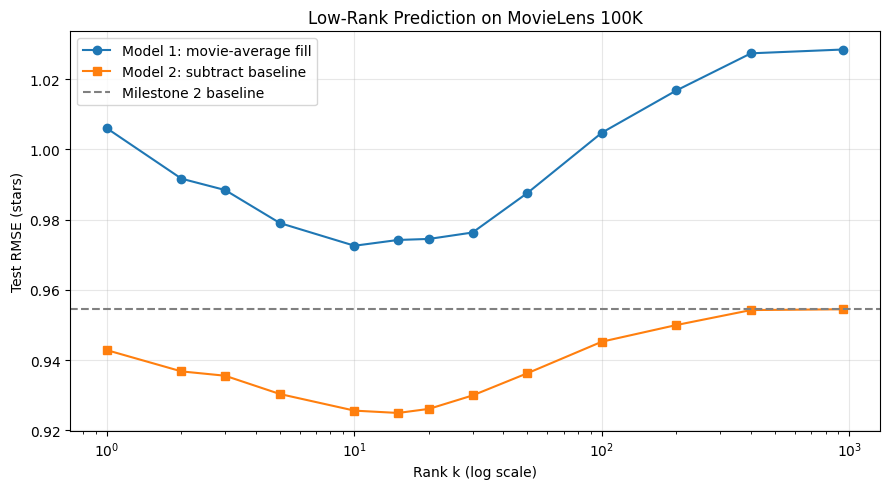

In [29]:
# Start a new figure.
plt.figure(figsize=(9, 5))

# Use a logarithmic horizontal axis because the ranks vary widely.
plt.semilogx(ks, err1, "o-", label="Model 1: movie-average fill")
plt.semilogx(ks, err2, "s-", label="Model 2: subtract baseline")

# Show the Milestone 2 baseline for comparison.
plt.axhline(
    score(B),
    color="gray",
    linestyle="--",
    label="Milestone 2 baseline"
)

# Label the graph.
plt.xlabel("Rank k (log scale)")
plt.ylabel("Test RMSE (stars)")
plt.title("Low-Rank Prediction on MovieLens 100K")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save the graph before displaying it.
plt.savefig("rmse_vs_k.png", dpi=150)
plt.show()

### Results

Model 1 had its lowest test RMSE of approximately 0.9726 at k = 10.
It did not beat the baseline RMSE of 0.9545. Most entries in the
filled matrix are movie-average guesses, which strongly influence
the approximation.

Model 2 performed better after subtracting the baseline. Its lowest
test RMSE was approximately 0.9250 at k = 15, about a 3.1% reduction
from the baseline.

Both models initially improve as k increases, but their errors later
rise. Keeping more components does not necessarily improve predictions:
the approximation increasingly reproduces the filled matrix, including
its temporary guesses.

At full rank, Model 1 returns the movie-average RMSE of 1.0284.
Model 2 returns the baseline RMSE of 0.9545. These match our
Milestone 2 results.

These best ranks were identified using the test set, so this comparison
is exploratory. We will choose a rank using validation data in Exercise 4.


## Model 3: Iterative SVD Imputation

Model 2 starts missing residuals at zero and computes one approximation.
Model 3 uses that approximation to update the missing residuals,
then computes another approximation.

We repeat this process 15 times. After each round, we restore the
observed training residuals and update only the missing entries.
The hidden test ratings are never used to fill the gaps.

In [30]:
def iterative_svd_predict(R, k, n_iter=15):
    """Predict ratings by repeatedly updating missing residuals."""

    # Identify observed training ratings.
    known = ~np.isnan(R)

    # Calculate the baseline using only the supplied ratings.
    B = baseline_matrix(R)

    # Start missing residuals at zero.
    X = np.where(known, R - B, 0.0)

    for step in range(n_iter):
        # Find a rank-k approximation of the current residual matrix.
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)

        # Restore observed residuals and refill only the gaps.
        X = np.where(known, R - B, L)

    # Add the baseline back to return predictions to the star scale.
    return L + B

The function starts with the same residual matrix as Model 2.
Each round produces a low-rank approximation called L.

The next round uses the original residuals at observed positions
and the new estimates at missing positions. Finally, we add the
baseline back to obtain predicted star ratings.

The function returns the final low-rank prediction plus the baseline.
We clip predictions to 1–5 when displaying or scoring them.

### Try Model 3 on the Toy Matrix

First, we use the small matrix from Milestone 1.
We keep the same user names used in our first notebook.

With k = 1, we check whether one component captures the main
action-versus-romance preference pattern.

In [31]:
# Use the same ratings and user names as our Milestone 1 notebook.
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],
    [4, np.nan, 5, 2, 1, 1],
    [5, 5, np.nan, 1, 2, np.nan],
    [1, 2, 1, 5, 4, np.nan],
    [np.nan, 1, 2, 4, 5, 5],
    [2, 1, np.nan, 5, np.nan, 4]
])

users = ["Josh", "Anna", "Simon", "Ethan", "Tobi", "Rose"]
movies = [
    "Action 1", "Action 2", "Action 3",
    "Romance 1", "Romance 2", "Romance 3"
]

# Calculate baseline and iterative predictions.
B_toy = baseline_matrix(toy)
P_toy = np.clip(iterative_svd_predict(toy, k=1), 1, 5)

# Display predictions only for the eight missing ratings.
for row, col in np.argwhere(np.isnan(toy)):
    print(
        f"{users[row]:6s} | {movies[col]:10s} | "
        f"Baseline: {B_toy[row, col]:.1f} | "
        f"Model 3: {P_toy[row, col]:.1f}"
    )

Josh   | Romance 2  | Baseline: 3.4 | Model 3: 2.1
Anna   | Action 2   | Baseline: 2.1 | Model 3: 3.2
Simon  | Action 3   | Baseline: 3.5 | Model 3: 5.0
Simon  | Romance 3  | Baseline: 3.1 | Model 3: 1.4
Ethan  | Romance 3  | Baseline: 2.5 | Model 3: 4.0
Tobi   | Action 1   | Baseline: 3.8 | Model 3: 2.6
Rose   | Action 3   | Baseline: 3.2 | Model 3: 1.4
Rose   | Romance 2  | Baseline: 3.0 | Model 3: 4.5


This comparison shows how the baseline and Model 3 predict the eight
missing ratings. The baseline uses overall user and movie effects,
while Model 3 can also capture patterns in individual preferences.

We can compare these predictions with our guesses from Milestone 1.
However, those guesses are not known answers, so this example checks
whether the predictions seem reasonable rather than measuring accuracy.

In [ ]:
# Try four ranks on the full MovieLens training matrix.
ks3 = [2, 5, 10, 20]
err3 = []

for k in ks3:
    # Each call performs 15 SVD rounds.
    P3 = iterative_svd_predict(R, k, n_iter=15)

    # Score the predictions on the same test set as the other models.
    model3_error = score(P3)
    err3.append(model3_error)

    print(f"k = {k:2d} | Model 3 test RMSE: {model3_error:.4f}")

k =  2 | Model 3 test RMSE: 0.9291


We test Model 3 at four ranks, using 15 rounds for each rank.
Every result uses the same hidden test ratings as the earlier models.

Repeated updates may improve the predictions, but larger ranks and
more rounds do not guarantee better results. We compare the measured
errors before deciding which settings worked best in this experiment.

### Model 3 Results

On the toy matrix, Model 3 captures the action-versus-romance pattern.
For example, it predicts 5.0 for Simon on Action 3 and 1.4 on Romance 3.
These predictions agree with the direction of our Milestone 1 guesses,
although they do not always match our guessed ratings exactly.

On MovieLens, Model 3 produced these test RMSE values:

| Rank k | Test RMSE |
|---|---|
| 2 | 0.9291 |
| 5 | 0.9206 |
| 10 | 0.9347 |
| 20 | 0.9780 |

The best rank tested was k = 5, with RMSE 0.9206. This is approximately
3.6% lower than the baseline RMSE of 0.9545 and slightly better than
Model 2's best result of 0.9250.

Increasing the rank beyond 5 made the test predictions worse in this
experiment. At k = 20, Model 3 was worse than the baseline.
This shows that a more detailed approximation does not necessarily
generalize better to hidden ratings.

These comparisons are exploratory because we inspected test scores
at several ranks.